# Beach bird detection — CNN

Small network: Conv, BatchNorm, ReLU, then a bird-score map. Peaks on the map become boxes.

The next cell trains for **30 epochs** at 512px and saves the best epoch to `cnn.pt`. On this CPU that is about 20 minutes.

**mAP@0.5** means a box counts only when it covers at least half a real bird. The 0.5 is that overlap. The score is whatever this training prints.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if not (ROOT / "dataset").is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "trials"))
import detector as det

EPOCHS = 30
SAVE = ROOT / "notebooks" / "cnn.pt"
det.train(EPOCHS, 1e-3, 4, False, 1.0, 512, str(SAVE), 0, "")

caching images at 512px ...


train 1369  val 291  epochs 30  batch 4  input 512  out 128  params 190,341


epoch  1  train 3.723  val mAP 0.0045  recall 0.072  44s  saved


epoch  2  train 3.425  val mAP 0.0010  recall 0.012  87s


epoch  3  train 3.245  val mAP 0.0308  recall 0.215  129s  saved


epoch  4  train 3.198  val mAP 0.0325  recall 0.175  176s  saved


... (23 outputs left out)

epoch 28  train 2.387  val mAP 0.1615  recall 0.406  1232s


epoch 29  train 2.425  val mAP 0.0708  recall 0.319  1277s


epoch 30  train 2.402  val mAP 0.1225  recall 0.371  1322s


best val mAP 0.1664 at epoch 24  -> notebooks/cnn.pt


Green is the label. Red is the best epoch.

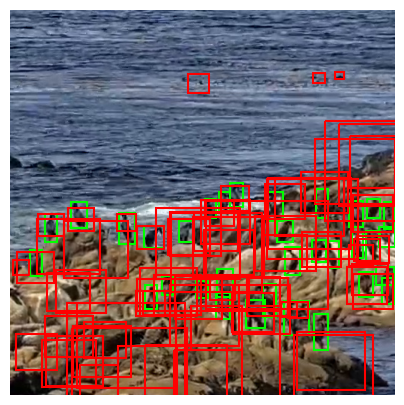

291 val images


In [2]:
%matplotlib inline
import os

import matplotlib.pyplot as plt
import numpy as np
import torch
from PIL import Image

model, log_wh, _ = det.load_model(str(SAVE))
val = det.load_split("val")
path, gts = val[0]
with torch.no_grad():
    hm, wh, off = model(det.read_image(path).unsqueeze(0))
    boxes, scores = det.decode(hm.sigmoid(), wh, off, thr=0.1, log_wh=log_wh)
im = np.array(Image.open(path).convert("RGB"))
plt.figure(figsize=(5, 5))
plt.imshow(im)
ax = plt.gca()
k = det.SRC / det.IN
for x, y, w, h in gts:
    ax.add_patch(plt.Rectangle((x * k, y * k), w * k, h * k, fill=False, edgecolor="lime", lw=1.5))
for b, s in zip(boxes.tolist(), scores.tolist()):
    ax.add_patch(plt.Rectangle((b[0] * k, b[1] * k), b[2] * k, b[3] * k, fill=False, edgecolor="red", lw=1.5))
plt.axis("off")
plt.show()
print(len(val), "val images")